<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>



# جلسه ۵ — تجزیه مقادیر تکین (SVD): شهود هندسی
### مبانی ریاضی یادگیری ماشین | بخش دوم: جبر خطی پیشرفته

**اهداف یادگیری این جلسه:**
- درک شهودی این‌که هر تبدیل ماتریسی را می‌توان به سه مرحله‌ی ساده تجزیه کرد: چرخش -> کشش -> چرخش
- فهم فرمول $A = U \Sigma V^\top$ و معنای هر بخش آن
- محاسبه‌ی SVD با کد و تفسیر مقادیر تکین (Singular Values)
- درک این‌که چرا SVD برای **هر** ماتریسی (حتی غیرمربعی) قابل‌محاسبه است — برخلاف بردار/مقدار ویژه که فقط برای ماتریس مربعی تعریف می‌شود

> 📘 **جعبه واژه‌نامه** — هر جا اصطلاح تخصصی جدیدی به‌کار می‌رود، همین‌جا با یک مثال ساده و غیرتخصصی توضیح داده می‌شود. لازم نیست از قبل این کلمات را بلد باشید.

> **پیش‌مطالعه:** فصل ۴ *Mathematics for Machine Learning* (بخش SVD) + یادآوری بردار ویژه از جلسه‌ی قبل.


<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>



## 🎯 چالش واقعی این جلسه: چرا تبدیل یک دایره همیشه یک بیضی می‌شود؟

در نرم‌افزارهایی مثل  Photoshop وقتی یک شکل دایره‌ای را با ابزار Transform می‌کِشید، می‌چرخانید یا اریب می‌کنید (Skew)، نتیجه‌اش همیشه یک **بیضی** است — نه یک شکل نامنظم و عجیب. چرا؟

و سؤال مهم‌تر: آیا می‌توانیم این بیضی را فقط با چند عدد ساده توصیف کنیم؟ (جهت محور بزرگ بیضی، جهت محور کوچک، و طول هر کدام) بیایید ببینیم.

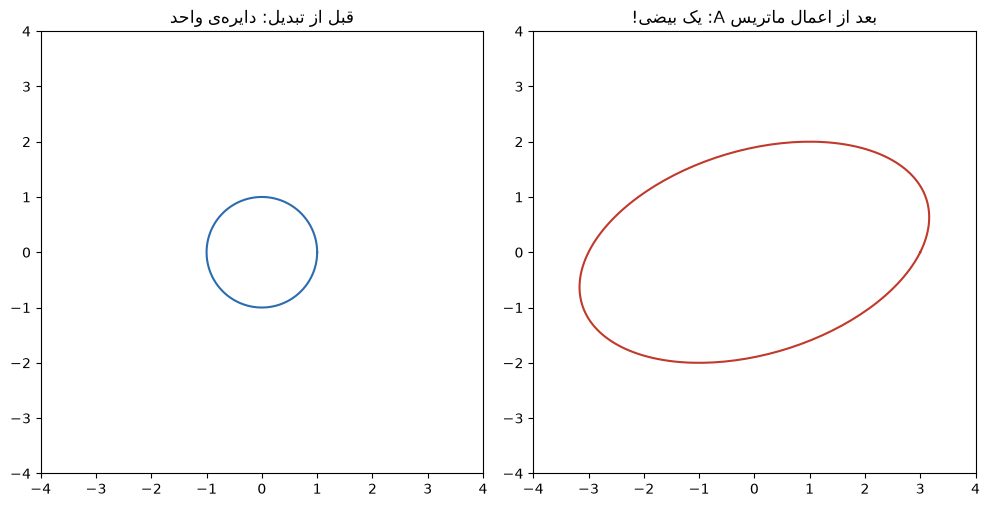

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# یک ماتریس ۲×۲ دلخواه (این می‌تواند نماینده‌ی هر تبدیلی باشد: چرخش دوربین، فیلتر تصویر، تغییر مقیاس داده و ...)
A = torch.tensor([[3.0, 1.0],
                   [0.0, 2.0]])


theta = torch.linspace(0, 2*np.pi, 200)  #Creates a 1D tensor of 200 evenly spaced values from 0 to 2π, including both endpoints.
circle = torch.stack([torch.cos(theta), torch.sin(theta)])  # دایره‌ی واحد، shape=(2, 200)

transformed = A @ circle  # اعمال تبدیل روی همه‌ی نقاط دایره

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].plot(circle[0], circle[1], color="#2b6cb0")
axes[0].set_title("قبل از تبدیل: دایره‌ی واحد")
axes[1].plot(transformed[0], transformed[1], color="#c0392b")
axes[1].set_title("بعد از اعمال ماتریس A: یک بیضی!")

for ax in axes:
    ax.set_aspect("equal"); ax.set_xlim(-4, 4); ax.set_ylim(-4, 4)
plt.tight_layout()
plt.show()



<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>



همان‌طور که دیدید، دایره به یک بیضی تبدیل شد. حالا با **تجزیه مقادیر تکین (Singular Value Decomposition – SVD)** دقیقاً همان چیزی را پیدا می‌کنیم که این بیضی را توصیف می‌کند: جهت محورهایش و طولشان.

<div dir="rtl" style="text-align:right">

---

## ۱. تجزیه طیفی (Spectral Decomposition)


**قضیه  (قضیهٔ طیفی، حالت حقیقی).** اگر $A\in\mathbb{R}^{n\times n}$ متقارن باشد ($A=A^\top$)، آنگاه ماتریس متعامد $Q\in O(n)$ و ماتریس قطری حقیقی $\Lambda=\operatorname{diag}(\lambda_1,\dots,\lambda_n)$ وجود دارند که
$$
A = Q\Lambda Q^\top = \sum_{i=1}^{n}\lambda_i\, q_i q_i^\top ,
$$
که در آن $q_i$ ستون‌های $Q$ هستند. هر $q_i q_i^\top$ تصویرگر متعامد روی $\operatorname{span}\{q_i\}$ است. این تصویرگرها دوبه‌دو متعامدند و مجموعشان $I$ است.

**قضیه (حالت مختلط).** ماتریس $A\in\mathbb{C}^{n\times n}$ نرمال است ($AA^*=A^*A$) اگر و تنها اگر ماتریس یکانی $U$ و ماتریس قطری $\Lambda$ موجود باشند که $A=U\Lambda U^*$.


- **محدودیت:** تجزیه طیفی فقط برای ماتریس‌های **مربعی نرمال** (از جمله متقارن/هرمیتی) وجود دارد، و فقط روی یک فضا عمل می‌کند ($\mathbb{R}^n\to\mathbb{R}^n$).

</div>

<div dir="rtl" style="text-align:right">

---
## ۲. تجزیه مقادیر منفرد (SVD)

### ۲.۱ تعریف و قضیهٔ وجود

**تعریف ۲ (SVD).** فرض کنید $A\in\mathbb{R}^{m\times n}$ و $p=\min\{m,n\}$. یک **تجزیه مقادیر منفرد** (کامل) برای $A$ عبارت است از
$$
A = U\Sigma V^\top ,
$$
که در آن $U\in O(m)$ و $V\in O(n)$ متعامدند و $\Sigma\in\mathbb{R}^{m\times n}$ «قطری» است، یعنی $\Sigma_{ii}=\sigma_i$ و سایر درایه‌ها صفرند، با
$$
\sigma_1\ge\sigma_2\ge\cdots\ge\sigma_p\ge 0 .
$$
اعداد $\sigma_i$ را **مقادیر منفرد**، ستون‌های $u_i$ از $U$ را **بردارهای منفرد چپ** و ستون‌های $v_i$ از $V$ را **بردارهای منفرد راست** می‌نامیم.

**قضیه (وجود).** هر ماتریس حقیقی $A\in\mathbb{R}^{m\times n}$ دارای SVD است.

*اثبات.* ماتریس $A^\top A\in\mathbb{R}^{n\times n}$ متقارن و نیمه‌مثبت‌معین است، زیرا $x^\top A^\top A x=\|Ax\|^2\ge0$. طبق قضیهٔ ۱ داریم $A^\top A=V\Lambda V^\top$ با $V\in O(n)$ و $\lambda_1\ge\cdots\ge\lambda_n\ge 0$. قرار می‌دهیم $\sigma_i=\sqrt{\lambda_i}$ و $r=\#\{i:\sigma_i>0\}$.

برای $i\le r$ تعریف می‌کنیم $u_i=Av_i/\sigma_i$. آنگاه
$$
u_i^\top u_j=\frac{v_i^\top A^\top A v_j}{\sigma_i\sigma_j}=\frac{\lambda_j\,v_i^\top v_j}{\sigma_i\sigma_j}=\delta_{ij},
$$
پس $\{u_1,\dots,u_r\}$ راست‌هنجار است. آن را به یک پایهٔ راست‌هنجار $\{u_1,\dots,u_m\}$ از $\mathbb{R}^m$ گسترش می‌دهیم.

برای $i>r$ داریم $\|Av_i\|^2=\lambda_i=0$، یعنی $Av_i=0$. پس برای همهٔ $i$ داریم $Av_i=\sigma_iu_i$ (با قرارداد $\sigma_i=0$ برای $i>r$)، یعنی $AV=U\Sigma$ و در نتیجه $A=U\Sigma V^\top$. $\blacksquare$

**صورت‌های هم‌ارز.** اگر $r=\operatorname{rank}A$:
- **فشرده (Compact):** $A=U_r\Sigma_rV_r^\top$ که $U_r\in\mathbb{R}^{m\times r}$ و $\Sigma_r\in\mathbb{R}^{r\times r}$ و $V_r\in\mathbb{R}^{n\times r}$.
- **مجموع رتبه‌یک‌ها:** $\displaystyle A=\sum_{i=1}^{r}\sigma_i\,u_iv_i^\top$.
- **نازک (Thin/Economy):** ستون‌های $U$ را تا $p$ نگه می‌داریم (در PyTorch با `full_matrices=False`).

### ۲.۲ ویژگی‌های اساسی

**قضیه** فرض کنید $A=U\Sigma V^\top$ یک SVD و $r$ تعداد مقادیر منفرد ناصفر باشد.

1. $\sigma_i^2$ ($i\le r$) مقادیر ویژهٔ ناصفر هر دو ماتریس $A^\top A$ و $AA^\top$ هستند. $v_i$ بردار ویژهٔ $A^\top A$ و $u_i$ بردار ویژهٔ $AA^\top$ است.
2. $\operatorname{rank}(A)=r$.
3. چهار زیرفضای بنیادی:
$$
\operatorname{col}(A)=\operatorname{span}\{u_1..u_r\},\quad
\ker(A^\top)=\operatorname{span}\{u_{r+1}..u_m\},
$$
$$
\operatorname{row}(A)=\operatorname{span}\{v_1..v_r\},\quad
\ker(A)=\operatorname{span}\{v_{r+1}..v_n\}.
$$
4. $\|A\|_2=\sigma_1$ و $\|A\|_F^2=\sum_i\sigma_i^2$ و $\|A\|_*=\sum_i\sigma_i$.
   تذکر.
   $\|\cdot\|_*$ نرم هسته‌ای (مجموع مقادیر منفرد) است.   
6. اگر $A$ مربعی و وارونپذیر باشد، عدد حالت $\kappa_2(A)=\|A\|_2\|A^{-1}\|_2=\sigma_1/\sigma_n$.
7. (یکتایی) مقادیر منفرد یکتا هستند. اگر مقادیر منفرد ناصفر متمایز باشند، بردارهای منفرد $(u_i,v_i)$ تا ضرب هم‌زمان در $-1$ یکتا هستند.

*اثبات (خلاصه).* (۱) $A^\top A=V\Sigma^\top\Sigma V^\top$ و $AA^\top=U\Sigma\Sigma^\top U^\top$، که هر دو تجزیهٔ طیفی‌اند. (۲) ضرب در ماتریس‌های وارونپذیر $U,V$ رتبه را حفظ می‌کند و $\operatorname{rank}\Sigma=r$. (۳) از $Av_i=\sigma_iu_i$ و $A^\top u_i=\sigma_iv_i$ نتیجه می‌شود. (۴) نرم‌های طیفی و فروبنیوس تحت ضرب در ماتریس متعامد ناوردا هستند. (۵) $A^{-1}=V\Sigma^{-1}U^\top$. $\blacksquare$

**ارتباط با تجزیه طیفی.** اگر $A$ متقارن باشد، $\sigma_i=|\lambda_i|$. اگر $A\succeq0$ باشد، SVD و تجزیه طیفی یکی هستند ($U=V=Q$ و $\Sigma=\Lambda$).

</div>

<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>




## بخش ۱: فرمول SVD و معنای هر بخش
تا اینجا دیدیم
هر ماتریس $A$ (حتی غیرمربعی!) را می‌توان این‌طور نوشت:

$$
A = U \Sigma V^\top
$$

- $V^\top$: یک **چرخش** (یا بازتاب) در فضای ورودی
- $\Sigma$: یک ماتریس قطری که فقط طول محورها را **می‌کِشد** (بدون چرخش) — اعداد روی قطرش را **مقادیر تکین (singular values)** می‌نامیم، همیشه نامنفی و از بزرگ به کوچک مرتب می‌شوند
- $U$: یک **چرخش** (یا بازتاب) دیگر، این‌بار در فضای خروجی

📘 یعنی هر تبدیل ماتریسی، هرچقدر هم پیچیده به‌نظر برسد، در واقع فقط «بچرخان -> بکِش -> دوباره بچرخان» است. دقیقاً همان چیزی که در چالش بالا با دایره و بیضی دیدیم: محورهای بیضی (که توسط $\Sigma$ تعیین می‌شوند) همان مقادیر تکین‌اند.

In [2]:
U, S, Vt = torch.linalg.svd(A)

print("U (چرخش خروجی):\n", U)
print("\nΣ (مقادیر تکین، طول محورهای بیضی):", S.tolist())
print("\nVᵀ (چرخش ورودی):\n", Vt)

# بررسی: آیا واقعا U @ diag(S) @ Vt همان A است؟
A_reconstructed = U @ torch.diag(S) @ Vt
print("\nبازسازی A از U, Σ, Vᵀ:\n", A_reconstructed)


U (چرخش خروجی):
 tensor([[ 0.9571, -0.2898],
        [ 0.2898,  0.9571]])

Σ (مقادیر تکین، طول محورهای بیضی): [3.2566165924072266, 1.8424029350280762]

Vᵀ (چرخش ورودی):
 tensor([[ 0.8817,  0.4719],
        [-0.4719,  0.8817]])

بازسازی A از U, Σ, Vᵀ:
 tensor([[3.0000, 1.0000],
        [0.0000, 2.0000]])


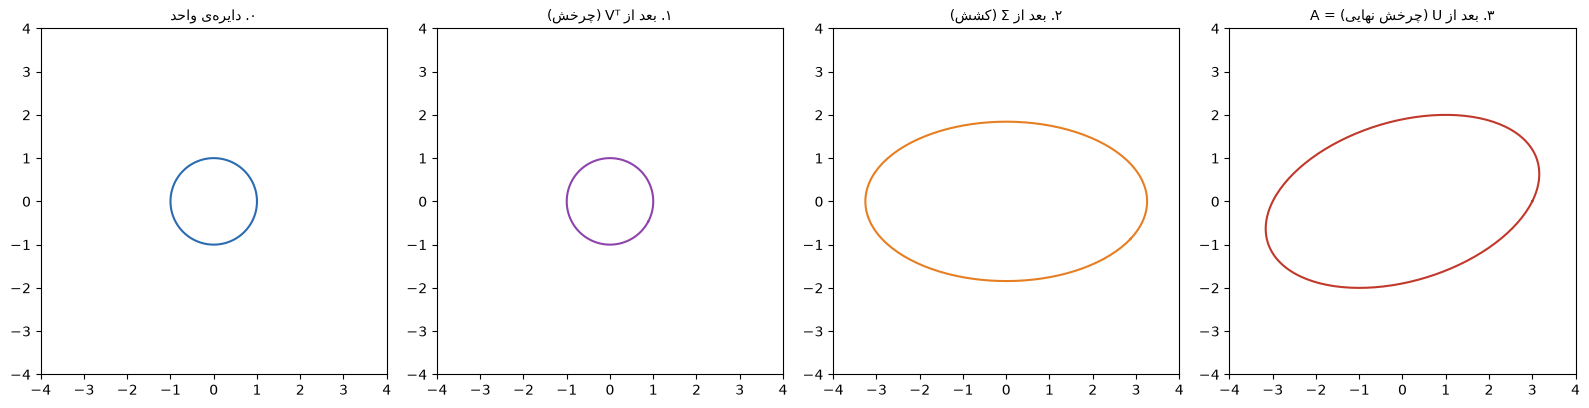

In [3]:
# تجسم گام‌به‌گام: دایره -> (اعمال Vᵀ) -> (اعمال Σ) -> (اعمال U)
step0 = circle
step1 = Vt @ step0
step2 = torch.diag(S) @ step1
step3 = U @ step2

fig, axes = plt.subplots(1, 4, figsize=(16, 4.3))
titles = ["۰. دایره‌ی واحد", "۱. بعد از Vᵀ (چرخش)", "۲. بعد از Σ (کشش)", "۳. بعد از U (چرخش نهایی) = A"]
colors = ["#2b6cb0", "#8e44ad", "#e67e22", "#c0392b"]
for ax, step, title, c in zip(axes, [step0, step1, step2, step3], titles, colors):
    ax.plot(step[0], step[1], color=c)
    ax.set_aspect("equal"); ax.set_xlim(-4, 4); ax.set_ylim(-4, 4)
    ax.set_title(title, fontsize=10)
plt.tight_layout()
plt.show()


<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>



### 🗣️ بحث دو‌نفره (Think–Pair–Share) — ۲ دقیقه
با نفر کناری‌تان مقایسه کنید: در جلسه‌ی قبل، بردار/مقدار ویژه را فقط برای ماتریس‌های **مربعی** تعریف کردیم. اینجا SVD را برای یک ماتریس مربعی دیدیم، اما گفتیم SVD برای هر ماتریسی (حتی مثلاً ماتریس ۱۰۰۰ کاربر × ۵۰ ویژگی) کار می‌کند. چرا فکر می‌کنید این تفاوت برای کار با داده‌های واقعی (که به‌ندرت مربعی‌اند) مهم است؟

<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>





### ✅ چرا SVD برای ماتریس‌های غیرمربعی مهم است؟

**۱. داده‌ی واقعی تقریباً هیچ‌وقت مربعی نیست.** در یک جدول داده، هر سطر یک نمونه (مثلاً یک کاربر) و هر ستون یک ویژگی است. تعداد کاربرها و تعداد ویژگی‌ها معمولاً برابر نیست؛ مثلاً ۱۰۰۰ کاربر و ۵۰ ویژگی، یعنی یک ماتریس $1000 \times 50$.

**۲. چرا بردار/مقدار ویژه برای چنین ماتریسی معنا ندارد؟** معادله‌ی $Av = \lambda v$ می‌گوید «بعد از اعمال $A$، بردار همان جهت قبلی را دارد و فقط کشیده شده». برای این مقایسه، $v$ و $Av$ باید در یک فضا باشند. اگر $A$ ماتریس $1000 \times 50$ باشد:

- ورودی $v$ در فضای ۵۰‌بعدی (فضای ویژگی‌ها) است،
- خروجی $Av$ در فضای ۱۰۰۰‌بعدی (فضای کاربرها) است.

این دو فضا حتی بعد یکسان ندارند، پس «هم‌جهت بودن» $v$ و $Av$ بی‌معناست.

**۳. SVD این مشکل را چطور حل می‌کند؟** به‌جای یک پایه‌ی مشترک، برای هر فضا یک پایه‌ی جداگانه می‌گیرد:

$$
A v_i = \sigma_i u_i
$$

- $v_i$ در فضای ورودی (ویژگی‌ها، ۵۰‌بعدی) است،
- $u_i$ در فضای خروجی (کاربرها، ۱۰۰۰‌بعدی) است،
- $\sigma_i$ (مقدار تکین) می‌گوید $v_i$ هنگام عبور از $A$ چقدر کشیده می‌شود.

یعنی به‌جای «هم‌جهت ماندن»، می‌گوییم هر جهت ورودی به یک جهت مشخص در خروجی نگاشت می‌شود. این برای هر شکلی از ماتریس کار می‌کند. در کد جلسه هم دیدیم که برای ماتریس
$6 \times 4$،
شکل‌ها

`U: (6,4)`، `Σ: (4,)` و `Vᵀ: (4,4)` 

بودند.

**۴. تفاوت‌های عملی مهم دیگر:**

| | بردار/مقدار ویژه | SVD |
|---|---|---|
| شکل ماتریس | فقط مربعی | هر ماتریسی |
| وجود تجزیه | همیشه تضمین نیست (ممکن است مقادیر ویژه موهومی باشند یا ماتریس قطری‌پذیر نباشد) | همیشه وجود دارد |
| مقادیر | ممکن است منفی یا موهومی باشند | مقادیر تکین همیشه حقیقی و نامنفی‌اند |
| پایه‌ها | ممکن است متعامد نباشند | $U$ و $V$ همیشه متعامدند |

📌 **یک راه‌حل جایگزین و محدودیتش:** می‌شود از ماتریس مربعی $A^\top A$ (که اینجا $50 \times 50$ و متقارن است) بردار ویژه گرفت. این بردارهای ویژه همان ستون‌های $V$ هستند و مقادیر ویژه‌اش $\sigma_i^2$ می‌شود. پس SVD و بردار ویژه به هم مربوط‌اند. اما ساختن $A^\top A$ در محاسبات عددی دقت را کم می‌کند (حساسیت عددی مسئله را به توان دو می‌رساند)، و فقط یک سمت را به ما می‌دهد. SVD هر دو سمت را مستقیم و پایدارتر حساب می‌کند.

**۵. چرا برای پروژه‌ی شما مهم است؟** چون تقریباً هر کاری که روی داده‌ی واقعی می‌خواهیم بکنیم (فشرده‌سازی، حذف نویز، سیستم پیشنهادگر در جلسه‌ی ۶، کاهش ابعاد با PCA در جلسه‌ی ۷) به شکل «جدول نمونه × ویژگی» شروع می‌شود، و SVD ابزاری است که مستقیم روی همین جدول، بدون هیچ تبدیل اضافه، کار می‌کند.

<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>




## بخش ۲: SVD روی یک ماتریس غیرمربعی (مثل داده‌ی واقعی)

📘 در دنیای واقعی، داده‌ی شما تقریباً هیچ‌وقت مربعی نیست — مثلاً یک جدول با ۶ کاربر و ۴ ویژگی، یک ماتریس $6 \times 4$ است. ببینیم SVD روی چنین ماتریسی چه شکلی است.

In [4]:
# یک ماتریس داده‌ی غیرمربعی: ۶ "کاربر" در ۴ "ویژگی"
data_matrix = torch.tensor([
    [5.0, 3.0, 0.0, 1.0],
    [4.0, 0.0, 0.0, 1.0],
    [1.0, 1.0, 0.0, 5.0],
    [1.0, 0.0, 0.0, 4.0],
    [0.0, 1.0, 5.0, 4.0],
    [0.0, 0.0, 5.0, 4.0],
])

U, S, Vt = torch.linalg.svd(data_matrix, full_matrices=False)
print("shape داده:", tuple(data_matrix.shape))
print("shape U:", tuple(U.shape), " | shape Σ:", tuple(S.shape), " | shape Vᵀ:", tuple(Vt.shape))
print("\nمقادیر تکین:", S.tolist())
print("\n📌 توجه کنید مقدار تکین اول خیلی بزرگ‌تر از بقیه است —")
print("   یعنی بیشتر «اطلاعات» این جدول را می‌توان با یک بُعد اصلی خلاصه کرد.")
print("   این ایده، پایه‌ی مستقیم جلسه‌ی بعد (فشرده‌سازی و سیستم‌های پیشنهادگر) است.")


shape داده: (6, 4)
shape U: (6, 4)  | shape Σ: (4,)  | shape Vᵀ: (4, 4)

مقادیر تکین: [10.504961013793945, 6.9459099769592285, 4.061274528503418, 1.9764100313186646]

📌 توجه کنید مقدار تکین اول خیلی بزرگ‌تر از بقیه است —
   یعنی بیشتر «اطلاعات» این جدول را می‌توان با یک بُعد اصلی خلاصه کرد.
   این ایده، پایه‌ی مستقیم جلسه‌ی بعد (فشرده‌سازی و سیستم‌های پیشنهادگر) است.


## بخش ۳: کارگاه عملی — روی داده‌ی پروژه‌ی خودتان

یک ماتریس کوچک از داده‌ی پروژه‌ی خودتان بسازید (چند سطر = چند نمونه/کاربر، چند ستون = چند ویژگی؛ لازم نیست مربعی باشد). سپس:

1. SVD آن را حساب کنید.
2. به مقادیر تکین نگاه کنید — آیا یکی یا دوتای اول خیلی بزرگ‌تر از بقیه‌اند؟
3. یک جمله بنویسید: اگر فقط بزرگ‌ترین مقدار تکین را نگه می‌داشتیم، فکر می‌کنید چقدر از «اطلاعات» داده‌تان را از دست می‌دادیم؟

In [ ]:
# فضای کار تیم شما 👇
my_data_matrix = torch.tensor([[...]])  # TODO: چند سطر × چند ستون از داده‌ی پروژه‌تان

U, S, Vt = torch.linalg.svd(my_data_matrix, full_matrices=False)
print("مقادیر تکین:", S.tolist())


In [3]:
import numpy as np

my_data_matrix = np.array([
    [ 3.6368, 2, 5.0, 94.5972,  4.6915,  3.4481],  # scenario 1, obs 1
    [14.6912, 5, 5.0, 94.5972,  8.7467, 12.1935],
    [ 4.8294, 3, 5.0, 94.5972,  5.0226,  4.7193],
    [14.3751, 4, 4.0, 90.4430,  8.3229, 13.5728],  # scenario 2, obs 1
    [ 2.2588, 1, 4.0, 90.4430,  9.5608, -0.0143],
    [ 0.5764, 1, 4.0, 90.4430,  7.4303, -3.8484],
    [ 9.8323, 4, 2.0, 95.5693,  7.9906,  4.9662],  # scenario 3, obs 1
    [ 6.1229, 1, 2.0, 95.5693, 10.4923, -2.4272],
    [ 5.8172, 3, 1.0, 95.3916,  5.8896,  4.6616],  # scenario 4, obs 1
    [ 7.8440, 2, 1.0, 95.3916,  9.0408,  0.7681],
    [ 7.0268, 1, 4.0, 90.0889, 11.7852, -1.5209],  # scenario 5, obs 1
    [13.8996, 5, 4.0, 90.0889,  6.6688, 10.0405],
], dtype=np.float64)

# استانداردسازی ستون‌ها
X = (my_data_matrix - my_data_matrix.mean(axis=0)) / my_data_matrix.std(axis=0)

U, S, Vt = np.linalg.svd(X, full_matrices=False)
print("مقادیر تکین:", np.round(S, 4).tolist())

مقادیر تکین: [5.8448, 4.2024, 3.8206, 2.1046, 0.8861, 0.6052]


Bar the third singular value, the first two are greater than the rest. Had we only kept the biggest SV, we would lose significant information (becasue the other two are big as well).

<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>






## جمع‌بندی و تکلیف

**تکلیف قبل از جلسه‌ی بعد:**
1. تمرین `# TODO` را کامل کنید.
2. کمی درباره‌ی سیستم‌های پیشنهادگر (Recommender Systems) فکر کنید: نتفلیکس یا اسپاتیفای چطور می‌داند شما چه چیزی را دوست خواهید داشت؟ (جلسه‌ی بعد دقیقاً همین را با ریاضیات امروز حل می‌کنیم)

**منابع این جلسه:**
- Deisenroth et al. — *Mathematics for Machine Learning*, فصل ۴ (بخش SVD)
- Strang — *Linear Algebra and Learning from Data*, فصل ۱ (SVD)
- Zhang et al. — *Dive into Deep Learning*, بخش جبر خطی عددی (پیاده‌سازی)
